# Notebook 03: Statistical Data Analysis & Visualizations

# 1. General Objective 
After completing Phase 02 (Data Cleaning), we now have a clean dataset containing images, captions, and manifests.

The objective of Phase 03 is to understand the content and characteristics of our dataset through statistical analysis and visualizations.

In this phase, we do not modify or preprocess the images. Instead, we study the information available in the captions and COCO object annotations.

# We want to answer questions such as:
- Are the captions generally short or long?
- Which words are used most frequently?
- What objects appear most often?
- How many objects are usually present in an image?
- Which grammatical categories are used in captions?
- Which colors, shapes, sizes, and contexts are mentioned?
- Where are objects positioned in relation to each other?
- Which object categories frequently appear together?
These analyses help us understand the dataset before using it in the Metadata-Filtered RAG project.

## Step 1: Import Required Libraries
 
# Library	General purpose
# JSON	
Read COCO annotation files.
##Regular Expressions (re)	Extract and process words from captions.
## Pathlib	
Manage project folders and file paths.
## Counter	
Count word and object frequencies.
## Pandas	
Organize data and calculate statistics.
## Matplotlib	
Create charts and visualizations.
## IPython.display	
Display formatted tables and results.

In [ ]:
import json
import re
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

## Step 2: Define Project Paths

### Description
This step defines the paths to the project directories,
annotation files, and cleaned datasets.

### Objective
Organize access to the data and prepare the directory
for saving statistical results and visualizations.

In [9]:
PROJECT_DIR = Path(r"C:\Users\PC\Desktop\Metadata_RAG_START")

DATA_DIR = PROJECT_DIR / "data"
ANNOTATIONS_DIR = PROJECT_DIR / "annotations"
VISUALIZATIONS_DIR = PROJECT_DIR / "visualizations"

VISUALIZATIONS_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CAPTIONS_PATH = DATA_DIR / "train_captions.csv"
VALIDATION_CAPTIONS_PATH = DATA_DIR / "validation_captions.csv"

TRAIN_MANIFEST_PATH = DATA_DIR / "train_manifest.csv"
VALIDATION_MANIFEST_PATH = DATA_DIR / "validation_manifest.csv"

INSTANCES_PATH = ANNOTATIONS_DIR / "instances_train2017.json"

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Visualizations directory:", VISUALIZATIONS_DIR)

Project directory: C:\Users\PC\Desktop\Metadata_RAG_START
Data directory: C:\Users\PC\Desktop\Metadata_RAG_START\data
Visualizations directory: C:\Users\PC\Desktop\Metadata_RAG_START\visualizations


## Step 3: Load Cleaned Dataset

### Description
This step loads the cleaned training and validation captions
and image manifests generated during the data cleaning phase.

### Objective
Prepare the cleaned data for statistical analysis while
preserving the separation between training and validation sets.

In [10]:
train_captions = pd.read_csv(TRAIN_CAPTIONS_PATH)
validation_captions = pd.read_csv(VALIDATION_CAPTIONS_PATH)

train_manifest = pd.read_csv(TRAIN_MANIFEST_PATH)
validation_manifest = pd.read_csv(VALIDATION_MANIFEST_PATH)

print("Training images:", len(train_manifest))
print("Validation images:", len(validation_manifest))

print("Training captions:", len(train_captions))
print("Validation captions:", len(validation_captions))

Training images: 9999
Validation images: 100
Training captions: 50018
Validation captions: 503


## Step 4: Caption Statistical Analysis

### Description
This step analyzes the textual characteristics of the
captions associated with the training dataset.

### Objective
Understand the length and vocabulary of the captions
through statistical measurements.

### Statistical Measures
- Average caption length.
- Minimum and maximum caption length.
- Median caption length.
- Vocabulary size (number of unique words).
- Total number of words.

In [11]:
# Calculate the number of words in each caption
train_captions["caption_length"] = (
    train_captions["caption"].str.split().str.len()
)

validation_captions["caption_length"] = (
    validation_captions["caption"].str.split().str.len()
)

# Display sample captions and their lengths
display(
    train_captions[["caption", "caption_length"]].head()
)

,caption,caption_length
0,Woman in swim suit holding parasol on sunny day.,9
1,"A woman posing for the camera, holding a pink,...",37
2,A woman in a floral swimsuit holds a pink umbr...,10
3,A woman with an umbrella near the sea,8
4,A girl in a bathing suit with a pink umbrella.,10


### 4.1. Caption Length Statistics

This section calculates descriptive statistics to examine
the distribution of caption lengths.

The results include the minimum, maximum, mean, median,
and standard deviation.

In [12]:
caption_statistics = train_captions["caption_length"].describe()

display(caption_statistics)

print("Minimum length:",
      train_captions["caption_length"].min())

print("Maximum length:",
      train_captions["caption_length"].max())

print("Average length:",
      round(train_captions["caption_length"].mean(), 2))

print("Median length:",
      train_captions["caption_length"].median())

count    50018.000000
mean        10.441761
std          2.380305
min          6.000000
25%          9.000000
50%         10.000000
75%         11.000000
max         47.000000
Name: caption_length, dtype: float64

Minimum length: 6
Maximum length: 47
Average length: 10.44
Median length: 10.0


### 4.2. Caption Length Distribution

A histogram is used to visualize the distribution of
caption lengths.

This visualization helps identify whether captions are
generally short, medium-sized, or long.

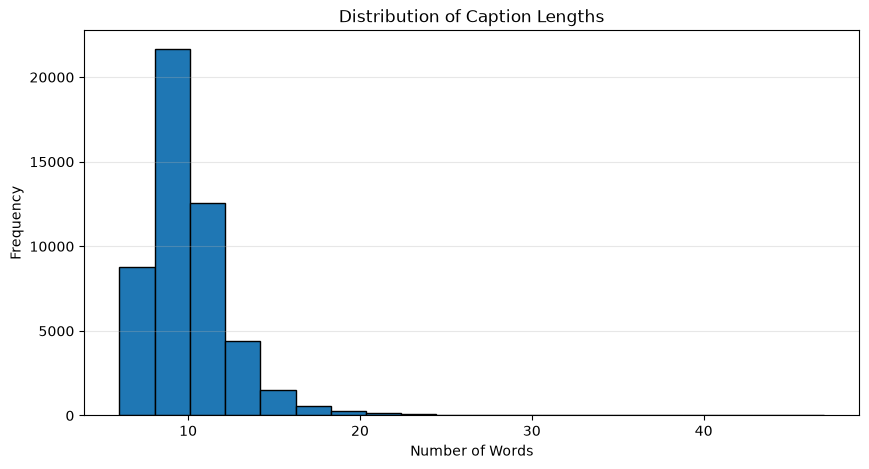

In [13]:
plt.figure(figsize=(10, 5))

plt.hist(
    train_captions["caption_length"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Caption Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "caption_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 4.3. Vocabulary Size Analysis

Vocabulary size represents the number of unique words
used in the training captions.

We convert all words to lowercase and remove punctuation
to obtain a consistent vocabulary.

In [14]:
all_words = []

for caption in train_captions["caption"]:
    words = re.findall(r"\b[a-zA-Z]+\b", caption.lower())
    all_words.extend(words)

word_counts = Counter(all_words)

total_words = len(all_words)
vocabulary_size = len(word_counts)

print("Total number of words:", total_words)
print("Vocabulary size:", vocabulary_size)

Total number of words: 523117
Vocabulary size: 9683


### 4.4. Results Interpretation

The training dataset contains 50,018 captions with a total
of 523,117 words and a vocabulary size of 9,683 unique words.

The average caption length is 10.44 words, while the median
is 10 words. Caption lengths range from 6 to 47 words.

The histogram shows that most captions are relatively short,
with the majority concentrated around 8 to 12 words.

These statistics provide an overview of the textual
characteristics and vocabulary diversity of the dataset.

## Step 5: Most Frequent Words Analysis

### Description
This step identifies the most frequently occurring words
in the training captions.

### Objective
Analyze the vocabulary distribution and identify the
most common words used to describe images.

### Method
- Convert all words to lowercase.
- Remove punctuation.
- Count word occurrences.
- Display the 20 most frequent words.

In [15]:
# Count word frequencies
word_counts = Counter(all_words)

# Extract the 20 most frequent words
top_words = word_counts.most_common(20)

# Create a DataFrame
top_words_df = pd.DataFrame(
    top_words,
    columns=["Word", "Frequency"]
)

display(top_words_df)

,Word,Frequency
0,a,82570
1,on,18333
2,of,17119
3,the,16884
4,in,15821
5,with,13000
6,and,11852
7,is,8253
8,man,6435
9,to,5604


### 5.1. Visualization of the Most Frequent Words

A bar chart is generated to visualize the 20 most frequent
words in the training captions.

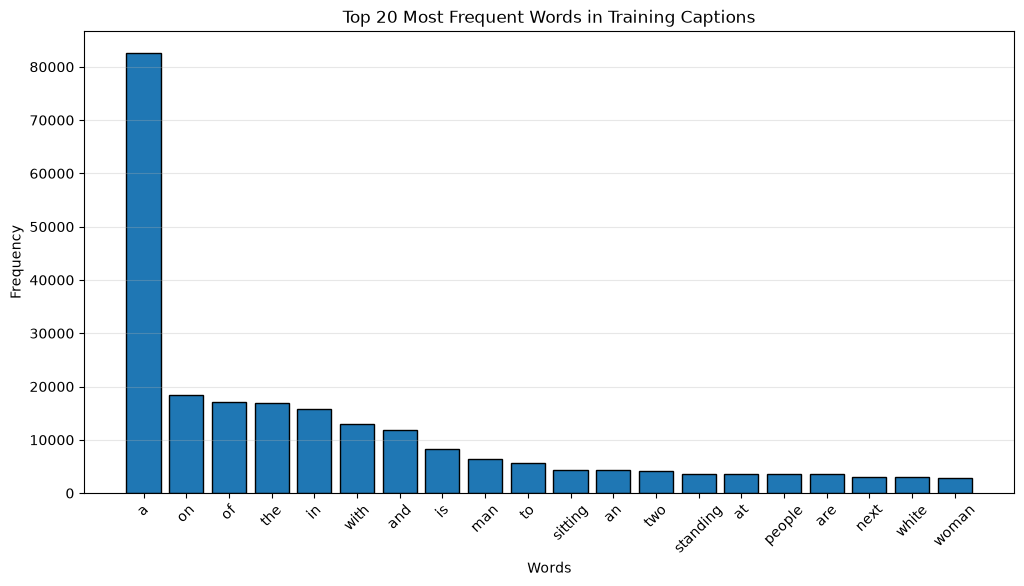

In [16]:
words = [item[0] for item in top_words]
frequencies = [item[1] for item in top_words]

plt.figure(figsize=(12, 6))

plt.bar(words, frequencies, edgecolor="black")

plt.title("Top 20 Most Frequent Words in Training Captions")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "most_frequent_words.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 5.2. Stop Words Removal

Common stop words such as "a", "the", "on", and "in"
occur frequently but provide limited information about
the visual content of images.

In this step, we remove these words to identify the
most meaningful terms used in image descriptions.

In [17]:
stop_words = {
    "a", "an", "the", "is", "are", "was", "were",
    "in", "on", "at", "of", "to", "and", "with",
    "for", "by", "from", "as", "it", "this", "that",
    "there", "has", "have", "his", "her", "their",
    "its", "be", "being", "while", "over", "under"
}

filtered_word_counts = Counter({
    word: count
    for word, count in word_counts.items()
    if word not in stop_words
})

top_meaningful_words = filtered_word_counts.most_common(20)

meaningful_words_df = pd.DataFrame(
    top_meaningful_words,
    columns=["Word", "Frequency"]
)

display(meaningful_words_df)

,Word,Frequency
0,man,6435
1,sitting,4418
2,two,4085
3,standing,3642
4,people,3529
5,next,3097
6,white,3069
7,woman,2876
8,street,2657
9,table,2437


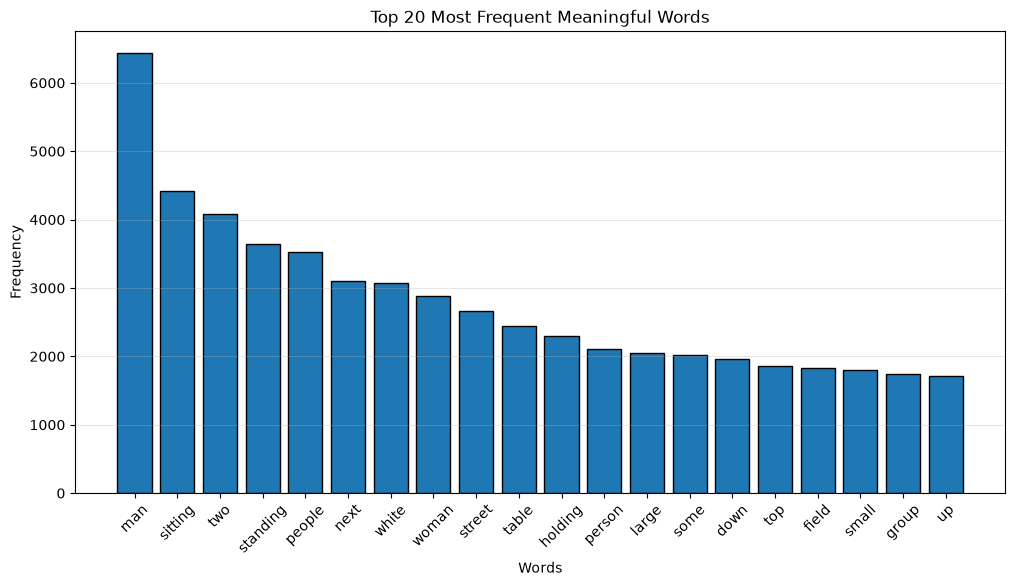

In [18]:
words = [item[0] for item in top_meaningful_words]
frequencies = [item[1] for item in top_meaningful_words]

plt.figure(figsize=(12, 6))

plt.bar(words, frequencies, edgecolor="black")

plt.title("Top 20 Most Frequent Meaningful Words")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "top_meaningful_words.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Step 6: Object Category Analysis

### Description
This step analyzes the object categories annotated in the
MS-COCO dataset using the instances annotation file.

### Objective
Identify the most frequent object categories in the selected
training and validation images.

### Method
- Load the COCO instances annotations.
- Map category IDs to category names.
- Filter annotations using the local image IDs.
- Count object category frequencies.
- Identify the top 50 most frequent categories.

In [19]:
with open(INSTANCES_PATH, "r", encoding="utf-8") as file:
    instances_data = json.load(file)

print("Total annotated images:", len(instances_data["images"]))
print("Total object annotations:", len(instances_data["annotations"]))
print("Total object categories:", len(instances_data["categories"]))

Total annotated images: 118287
Total object annotations: 860001
Total object categories: 80


### 6.1. Create Category Mapping

Each object annotation contains a category ID.
We create a dictionary to associate each category ID
with its corresponding category name.

In [20]:
category_mapping = {
    category["id"]: category["name"]
    for category in instances_data["categories"]
}

print("Number of categories:", len(category_mapping))

display(pd.DataFrame(
    list(category_mapping.items()),
    columns=["Category ID", "Category Name"]
).head(10))

Number of categories: 80


,Category ID,Category Name
0,1,person
1,2,bicycle
2,3,car
3,4,motorcycle
4,5,airplane
5,6,bus
6,7,train
7,8,truck
8,9,boat
9,10,traffic light


### 6.2. Filter Annotations for Local Images

The original COCO annotation file contains information
about a large collection of images.

We filter the annotations using the image IDs from our
cleaned training and validation manifests to analyze
only the images belonging to our project.

In [21]:
train_image_ids = set(train_manifest["image_id"])
validation_image_ids = set(validation_manifest["image_id"])

all_local_image_ids = train_image_ids.union(validation_image_ids)

local_annotations = [
    annotation
    for annotation in instances_data["annotations"]
    if annotation["image_id"] in all_local_image_ids
]

print("Training images:", len(train_image_ids))
print("Validation images:", len(validation_image_ids))
print("Total local images:", len(all_local_image_ids))
print("Object annotations in local images:", len(local_annotations))

Training images: 9999
Validation images: 100
Total local images: 10099
Object annotations in local images: 72998


### 6.3. Calculate Object Category Frequencies

We count how many times each object category appears
in the selected images.

The categories are sorted in descending order according
to their frequency.

In [22]:
category_counts = Counter(
    annotation["category_id"]
    for annotation in local_annotations
)

category_results = pd.DataFrame([
    {
        "Category": category_mapping[category_id],
        "Frequency": count
    }
    for category_id, count in category_counts.most_common()
])

display(category_results.head(20))

,Category,Frequency
0,person,22532
1,car,3706
2,chair,3398
3,book,2040
4,bottle,1964
5,cup,1612
6,dining table,1260
7,bowl,1179
8,traffic light,1106
9,handbag,1066


### 6.4. Top 50 Object Categories

We select the 50 most frequent object categories
to identify the dominant visual elements in the dataset.

In [23]:
top_50_categories = category_results.head(50).copy()

display(top_50_categories)

top_50_categories.to_csv(
    DATA_DIR / "top_50_object_categories.csv",
    index=False
)

,Category,Frequency
0,person,22532
1,car,3706
2,chair,3398
3,book,2040
4,bottle,1964
5,cup,1612
6,dining table,1260
7,bowl,1179
8,traffic light,1106
9,handbag,1066


### 6.5. Visualization of Top 50 Object Categories

A horizontal bar chart is used to visualize the 50 most
frequent object categories.

This visualization makes it easier to compare the
frequency of different objects in the dataset.

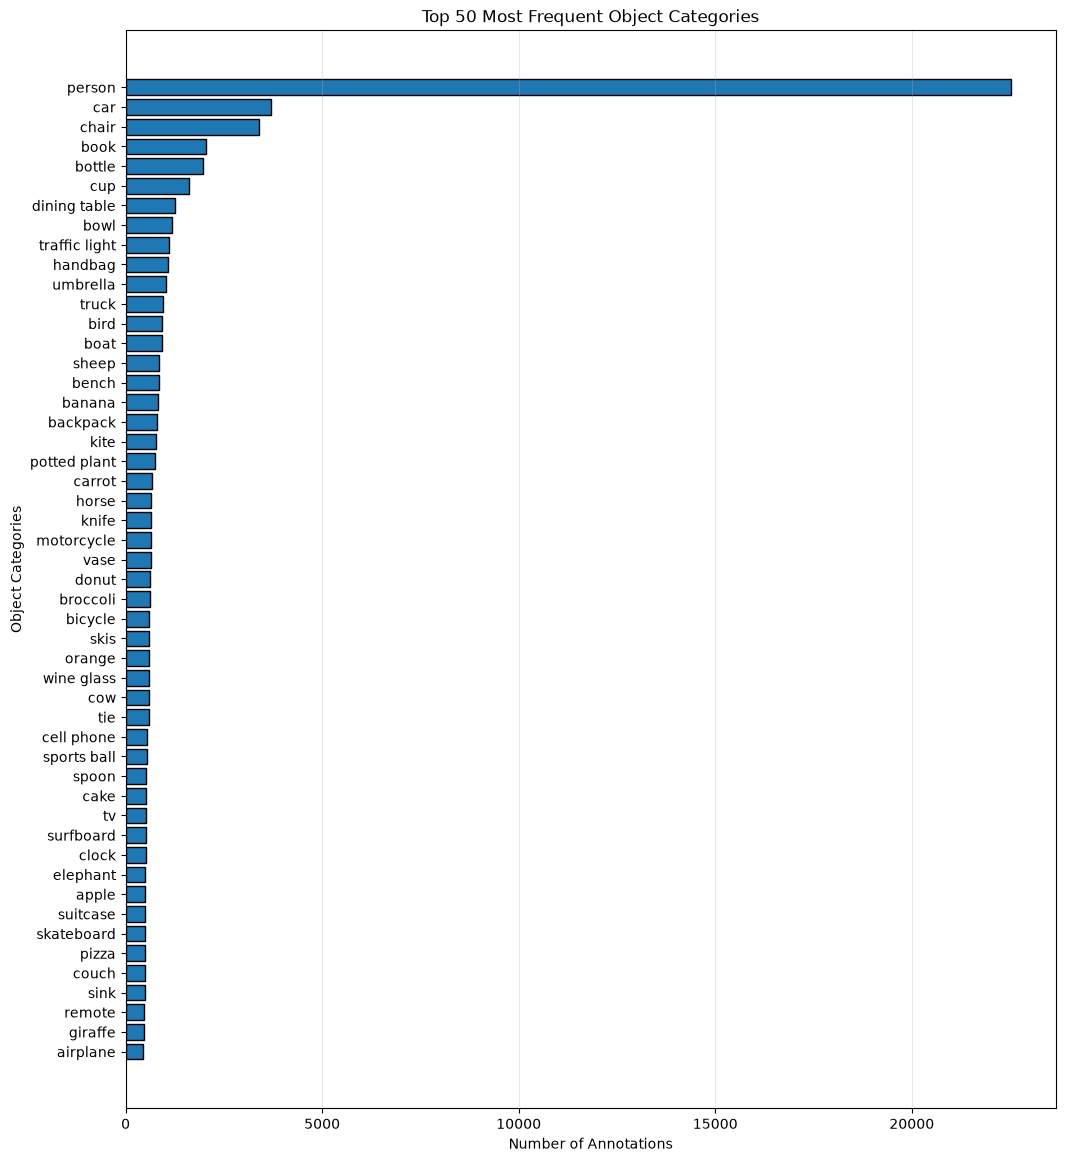

In [24]:
plt.figure(figsize=(12, 14))

plt.barh(
    top_50_categories["Category"].iloc[::-1],
    top_50_categories["Frequency"].iloc[::-1],
    edgecolor="black"
)

plt.title("Top 50 Most Frequent Object Categories")
plt.xlabel("Number of Annotations")
plt.ylabel("Object Categories")
plt.grid(axis="x", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "top_50_object_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 6.6. Results Interpretation

The selected dataset contains 72,998 object annotations
across 10,099 images.

The analysis identifies 80 COCO object categories.
The most frequent category is "person", with 22,532
annotations, followed by "car" with 3,706 annotations
and "chair" with 3,398 annotations.

These results show that people are the dominant objects
in the selected dataset, while other categories represent
different types of objects, including vehicles, furniture,
animals, and food.

The Top 50 categories provide an overview of the visual
content and object diversity of the dataset.

## Step 7: Scene Complexity Analysis

### Description
Scene complexity refers to the number of annotated objects
present in an image.

### Objective
Measure the complexity of image scenes by calculating
the number of object annotations per image.

### Statistical Measures
- Average number of objects per image.
- Minimum and maximum number of objects.
- Distribution of objects across images.

In [25]:
objects_per_image = Counter(
    annotation["image_id"]
    for annotation in local_annotations
)

scene_complexity = pd.DataFrame({
    "image_id": sorted(all_local_image_ids)
})

scene_complexity["object_count"] = (
    scene_complexity["image_id"]
    .map(objects_per_image)
    .fillna(0)
    .astype(int)
)

display(scene_complexity.head(10))

,image_id,object_count
0,36,2
1,73,2
2,89,10
3,109,8
4,196,42
5,247,8
6,263,2
7,308,13
8,312,6
9,315,40


### 7.1. Statistical Summary of Scene Complexity

We calculate descriptive statistics to understand
the distribution of annotated objects per image.

In [26]:
display(scene_complexity["object_count"].describe())

print(
    "Average objects per image:",
    round(scene_complexity["object_count"].mean(), 2)
)

print(
    "Minimum objects:",
    scene_complexity["object_count"].min()
)

print(
    "Maximum objects:",
    scene_complexity["object_count"].max()
)

count    10099.000000
mean         7.228240
std          7.374506
min          0.000000
25%          2.000000
50%          4.000000
75%         10.000000
max         78.000000
Name: object_count, dtype: float64

Average objects per image: 7.23
Minimum objects: 0
Maximum objects: 78


### 7.2. Distribution of Objects Per Image

A histogram is generated to visualize the distribution
of object counts across the selected images.

This provides an approximate indication of scene complexity.

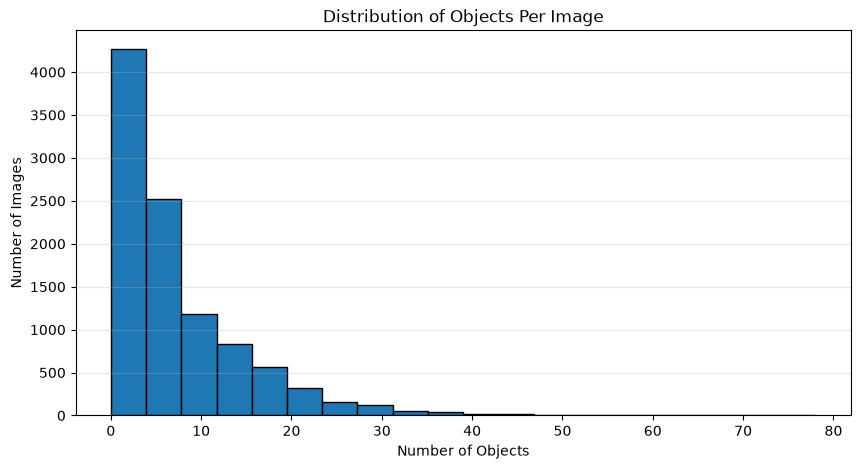

In [27]:
plt.figure(figsize=(10, 5))

plt.hist(
    scene_complexity["object_count"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Objects Per Image")
plt.xlabel("Number of Objects")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "scene_complexity_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 7.3. Results Interpretation

The scene complexity analysis was performed on 10,099 images.

The average number of object annotations per image is 7.23,
with a median of 4 objects. The number of annotations ranges
from 0 to 78 per image.

The difference between the mean and median indicates that
some images contain considerably more annotated objects
than others.

The standard deviation of 7.37 also shows a noticeable
variation in scene complexity across the dataset.

These results provide an approximate measure of scene
complexity based on COCO object annotations.

### 7.4. Verification of Images Without Object Annotations

This step identifies images that have no object annotations
in the selected COCO instances dataset.

The verification helps detect missing annotation records
or possible inconsistencies between image IDs and annotations.

In [28]:
# Identify images with zero object annotations
images_without_objects = scene_complexity[
    scene_complexity["object_count"] == 0
].copy()

print("Images without object annotations:",
      len(images_without_objects))

display(images_without_objects.head(20))

Images without object annotations: 85


,image_id,object_count
69,4308,0
76,4517,0
176,9778,0
178,9809,0
370,20490,0
633,35475,0
689,39475,0
735,42345,0
862,49741,0
864,49883,0


In [29]:
# Check whether these image IDs exist in the instances image records
instances_image_ids = {
    image["id"] for image in instances_data["images"]
}

images_without_instances_info = images_without_objects[
    ~images_without_objects["image_id"].isin(instances_image_ids)
]

print(
    "Images missing from instances image records:",
    len(images_without_instances_info)
)

Images missing from instances image records: 0


### 7.5. Results Interpretation

The verification confirms that all images with zero object
annotations are present in the original COCO image records.

Therefore, these images are not missing from the dataset.
However, they do not have corresponding object annotations
in the selected instances annotation file.

These images are retained in the dataset, and their object
count is recorded as zero.

In [30]:
print("Total images without object annotations:",
      len(images_without_objects))

print("Percentage of images without object annotations:",
      round(
          len(images_without_objects) / len(scene_complexity) * 100,
          2
      ), "%")

Total images without object annotations: 85
Percentage of images without object annotations: 0.84 %


## Step 8: Caption POS Distribution

### Description
Part-of-Speech (POS) analysis identifies the grammatical categories
of words used in image captions.

The analysis focuses on three main categories:
- Nouns: words representing people, objects, and places.
- Verbs: words describing actions or states.
- Adjectives: words describing object properties or characteristics.

### Objective
Analyze the linguistic structure of captions by measuring the
frequency and distribution of nouns, verbs, and adjectives.

### Method
Use Natural Language Processing (NLP) to tokenize captions and
assign a grammatical category to each word.

### 8.2. Install NLTK Library

The Natural Language Toolkit (NLTK) is a Python library used
for natural language processing.

It provides tools for tokenization and Part-of-Speech tagging.

In [31]:
%pip install nltk

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 15.5 MB/s  0:00:00

   ---------------------------------------- 0/6 [tqdm]
   ---------------------------------------- 0/6 [tqdm]
   ------ --------------------------------- 1/6 [regex]
   ------------- -------------------------- 2/6 [cloudpickle]
   -------------------- ------------------- 3/6 [click]
   -------------------- ------------------- 3/6 [click]
   -------------------------- ------------- 4/6 [joblib]
   -------------------------- ------------- 4/6 [joblib]
   -------------------------- ------------- 4/6 [joblib]
   -------------------------- ------------- 4/6 [joblib]
   -------------------------- ------------- 4/6 [joblib]
   --------------------------------- ------ 5/6 [nltk]
   --------------------------------- ------ 5/6 [nltk]
   --------------------------------- ------ 5/6 [nltk]
   --------------------------------- ------ 5/6 [nltk]
   --------

### 8.3. Download Required NLP Resources

NLTK requires additional language resources to process English captions.

The following resources are downloaded:
- punkt_tab: used for sentence and word tokenization.
- averaged_perceptron_tagger_eng: used to identify grammatical categories.

These resources allow the system to analyze the words in each caption.

In [32]:
import nltk

nltk.download("punkt_tab")
nltk.download("averaged_perceptron_tagger_eng")

print("NLTK resources are ready.")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\PC\AppData\Roaming\nltk_data...


NLTK resources are ready.


[nltk_data]   Unzipping taggers\averaged_perceptron_tagger_eng.zip.


### 8.4. Identify Grammatical Categories

In this step, the training captions are processed using NLTK.

Each caption is tokenized into individual words, and each word
is assigned a Part-of-Speech tag.

The analysis counts three grammatical categories:
- NN: Nouns
- VB: Verbs
- JJ: Adjectives

The results provide the total frequency of each category
across all training captions.

In [33]:
from nltk.tokenize import word_tokenize
from nltk import pos_tag
from collections import Counter

pos_counts = Counter()

for caption in train_captions["caption"].dropna():
    words = word_tokenize(caption.lower())
    tagged_words = pos_tag(words)

    for word, tag in tagged_words:
        if tag.startswith("NN"):
            pos_counts["Nouns"] += 1
        elif tag.startswith("VB"):
            pos_counts["Verbs"] += 1
        elif tag.startswith("JJ"):
            pos_counts["Adjectives"] += 1

print("POS Distribution:")

for category, count in pos_counts.items():
    print(f"{category}: {count}")

POS Distribution:
Nouns: 184806
Adjectives: 43484
Verbs: 60166


### 8.5. Calculate POS Percentages

After identifying the grammatical categories, their percentages
are calculated relative to the total number of identified nouns,
verbs, and adjectives.

The results are organized into a DataFrame containing:
- POS Category
- Count
- Percentage

This allows us to compare the frequency of each grammatical category.

In [34]:
total_pos_words = sum(pos_counts.values())

pos_results = pd.DataFrame({
    "POS Category": list(pos_counts.keys()),
    "Count": list(pos_counts.values())
})

pos_results["Percentage"] = (
    pos_results["Count"] / total_pos_words * 100
).round(2)

display(pos_results)

,POS Category,Count,Percentage
0,Nouns,184806,64.07
1,Adjectives,43484,15.07
2,Verbs,60166,20.86


### 8.6. Visualize POS Distribution

A bar chart is created to visualize the frequency of nouns,
verbs, and adjectives in the training captions.

This visualization makes it easier to compare the grammatical
categories and understand the linguistic structure of the captions.

The generated chart is saved in the visualizations directory.

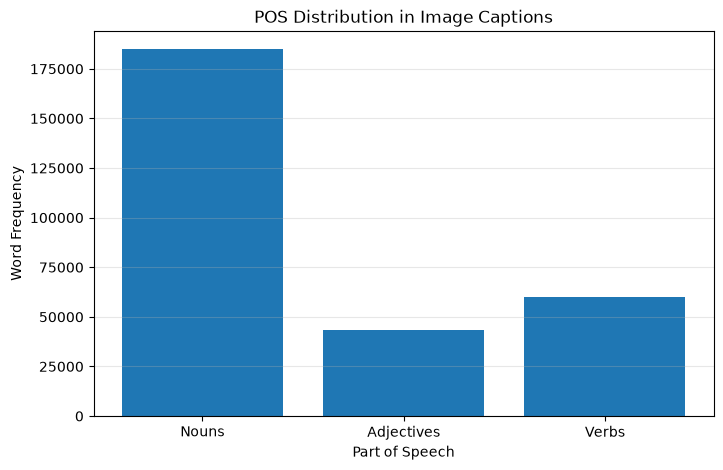

In [35]:
plt.figure(figsize=(8, 5))

plt.bar(
    pos_results["POS Category"],
    pos_results["Count"]
)

plt.title("POS Distribution in Image Captions")
plt.xlabel("Part of Speech")
plt.ylabel("Word Frequency")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "pos_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 8.7. Results Interpretation

The POS analysis shows that nouns represent the largest
grammatical category, accounting for 64.07% of the identified
words. This indicates that image captions mainly focus on
identifying people, objects, and other elements in the scenes.

Verbs represent 20.86% of the words, describing actions and
activities occurring in the images.

Adjectives account for 15.07%, providing additional descriptive
information about object properties and characteristics.

Overall, the results indicate that COCO captions are mainly
object-oriented, with verbs and adjectives contributing to
the description of actions and visual details.

## Step 9: Diversity Analysis

### Description
Diversity analysis examines the variety of visual attributes
and contexts mentioned in the image captions.

The analysis focuses on three main aspects:

- Colors: visual color descriptions such as red, blue, black, and white.
- Shapes and Sizes: descriptive terms such as round, small, large, and long.
- Context: scene descriptions such as indoor, outdoor, day, and night.

### Objective
Identify the diversity of descriptions used in the captions
and understand how visual characteristics and scene contexts
are represented in the dataset.

### Method
Keyword-based analysis is applied to the training captions.
The analysis is based on textual descriptions and does not
represent direct visual recognition.

### 9.1. Define Attribute Categories

In this step, dictionaries of keywords are created to identify
different visual attributes in the captions.

Three groups of keywords are considered:

- Colors: red, blue, green, black, white, and others.
- Shapes and Sizes: round, square, small, large, long, and others.
- Context: indoor, outdoor, day, and night.

These dictionaries will be used to count the occurrences
of each attribute in the training captions.

In [36]:
color_keywords = [
    "red", "blue", "green", "yellow", "black",
    "white", "brown", "orange", "pink", "purple",
    "gray", "grey"
]

shape_size_keywords = [
    "round", "square", "rectangular", "circular",
    "small", "large", "big", "tiny", "long",
    "short", "tall", "wide", "narrow"
]

context_keywords = [
    "indoor", "indoors", "outdoor", "outdoors",
    "inside", "outside", "day", "night",
    "sunny", "dark", "bright"
]

print("Attribute keyword dictionaries created.")

Attribute keyword dictionaries created.


### 9.2. Color Diversity Analysis

This step identifies color-related words in the training captions.

Each caption is searched for the predefined color keywords.
The frequency of each color is counted across all captions.

This analysis helps identify the most frequently mentioned
colors in the textual descriptions.

In [37]:
color_counts = Counter()

for caption in train_captions["caption"].dropna():
    words = re.findall(r"\b[a-zA-Z]+\b", caption.lower())

    for word in words:
        if word in color_keywords:
            color_counts[word] += 1

color_results = pd.DataFrame(
    color_counts.most_common(),
    columns=["Color", "Count"]
)

display(color_results)

,Color,Count
0,white,3069
1,black,1657
2,red,1412
3,blue,1164
4,green,1111
5,brown,729
6,yellow,662
7,orange,395
8,pink,268
9,gray,171


### 9.5. Color Distribution Visualization

A bar chart is created to display the frequency of color
descriptions found in the training captions.

The chart helps compare the use of different color terms
and identify the most frequently mentioned colors.

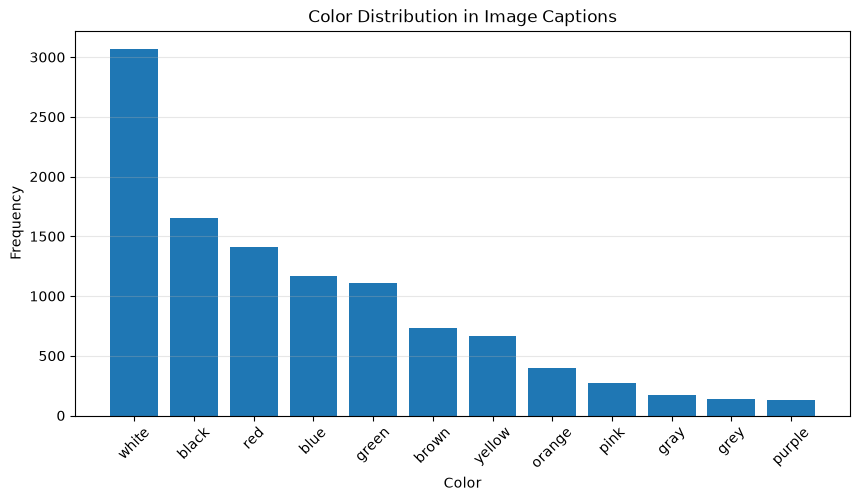

In [38]:
plt.figure(figsize=(10, 5))

plt.bar(
    color_results["Color"],
    color_results["Count"]
)

plt.title("Color Distribution in Image Captions")
plt.xlabel("Color")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "color_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.4. Shapes and Sizes Analysis

This step examines descriptive words related to object shapes
and sizes in the training captions.

The predefined keywords include terms such as small, large,
round, square, long, and tall.

The frequency of these terms is counted to understand
how often captions describe object dimensions and shapes.

In [39]:
shape_size_counts = Counter()

for caption in train_captions["caption"].dropna():
    words = re.findall(r"\b[a-zA-Z]+\b", caption.lower())

    for word in words:
        if word in shape_size_keywords:
            shape_size_counts[word] += 1

shape_size_results = pd.DataFrame(
    shape_size_counts.most_common(),
    columns=["Attribute", "Count"]
)

display(shape_size_results)

,Attribute,Count
0,large,2048
1,small,1794
2,big,447
3,tall,408
4,long,303
5,square,60
6,round,57
7,short,48
8,narrow,47
9,tiny,39


### 9.5. Shapes and Sizes Visualization

A bar chart is generated to visualize the frequency
of shape and size descriptions.

This visualization helps compare the descriptive attributes
used in the captions.

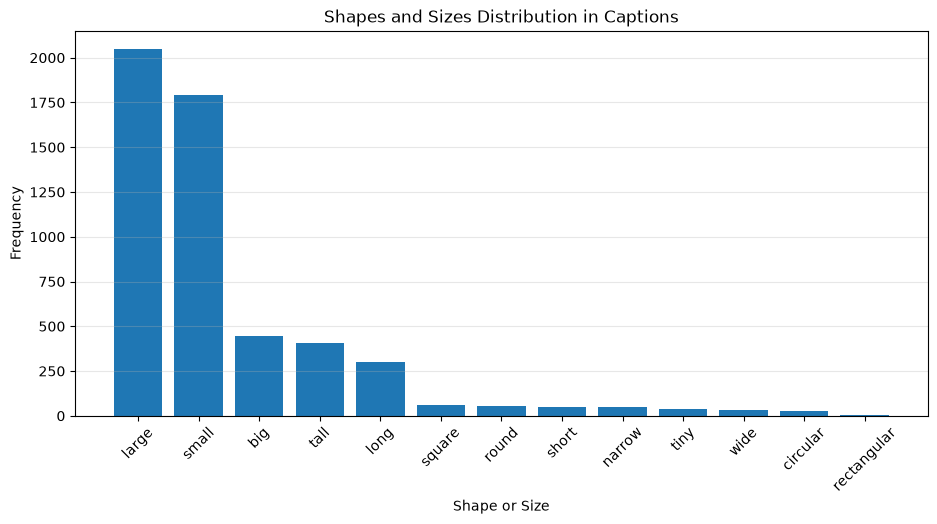

In [40]:
plt.figure(figsize=(11, 5))

plt.bar(
    shape_size_results["Attribute"],
    shape_size_results["Count"]
)

plt.title("Shapes and Sizes Distribution in Captions")
plt.xlabel("Shape or Size")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "shapes_sizes_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.6. Scene Context Analysis

This step identifies contextual keywords that describe
the environment or lighting conditions mentioned in captions.

The analysis considers:
- Indoor and outdoor environments.
- Inside and outside descriptions.
- Day and night conditions.
- Lighting descriptions such as sunny, dark, and bright.

The frequency of these keywords is calculated to explore
the contextual diversity of the dataset.

In [41]:
context_counts = Counter()

for caption in train_captions["caption"].dropna():
    words = re.findall(r"\b[a-zA-Z]+\b", caption.lower())

    for word in words:
        if word in context_keywords:
            context_counts[word] += 1

context_results = pd.DataFrame(
    context_counts.most_common(),
    columns=["Context", "Count"]
)

display(context_results)

,Context,Count
0,outside,651
1,inside,468
2,day,374
3,night,208
4,dark,145
5,outdoor,122
6,bright,118
7,sunny,105
8,outdoors,52
9,indoor,26


### 9.7. Scene Context Visualization

A bar chart is created to display the frequency of contextual
descriptions in the training captions.

This visualization provides an overview of how indoor,
outdoor, and lighting-related terms are represented
in the dataset.

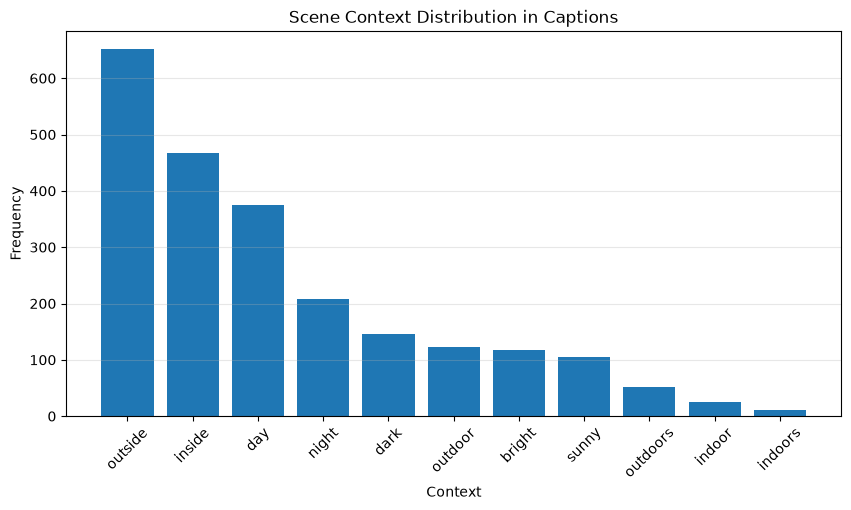

In [42]:
plt.figure(figsize=(10, 5))

plt.bar(
    context_results["Context"],
    context_results["Count"]
)

plt.title("Scene Context Distribution in Captions")
plt.xlabel("Context")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "context_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 9.9. Results Interpretation

The diversity analysis reveals different types of visual
descriptions used in the training captions.

**Color Diversity:**

White is the most frequently mentioned color, with 3,069
occurrences, followed by black (1,657), red (1,412),
and blue (1,164). These results show that color terms
provide important descriptive details in image captions.

**Shapes and Sizes Diversity:**

The terms large (2,048) and small (1,794) are the most
frequently used attributes. This indicates that captions
often describe the size of objects rather than their
geometric shapes.

**Scene Context Diversity:**

The term outside appears most frequently, with 651
occurrences, followed by inside (468), day (374),
and night (208). This demonstrates that captions
also describe environmental and lighting contexts.

**Conclusion:**

Overall, the analysis highlights the linguistic diversity
of COCO captions through color, size, shape, and context
descriptions. These attributes provide additional textual
information that can contribute to image understanding.

It should be noted that the results represent keyword
occurrences in captions, not verified visual attributes
or the number of images containing each attribute.

## Step 10: Spatial Relationships Analysis

### Description
Spatial relationship analysis examines the relative positions
of objects within images using their bounding box coordinates.

The COCO instances annotations provide bounding boxes in the
format [x, y, width, height].

Based on these coordinates, approximate spatial relationships
can be identified, such as:
- Left: one object's center is to the left of another.
- Right: one object's center is to the right of another.
- Above: one object's center is above another.
- Below: one object's center is below another.
- Overlap: two bounding boxes overlap significantly.

### Objective
Explore the spatial arrangement of annotated objects
and identify the most frequent geometric relationships.

### Method
Bounding box coordinates are used to calculate object centers
and intersection over union (IoU).

The extracted relationships are geometric approximations
and do not represent manually annotated semantic relationships.

### 10.1. Prepare Object Annotations

In this step, object annotations are filtered to include only
the images belonging to the cleaned training and validation sets.

Each annotation contains:
- image_id: the identifier of the image.
- category_id: the identifier of the object category.
- bbox: the bounding box coordinates [x, y, width, height].

The category identifiers are mapped to their corresponding
object names using the COCO categories information.

### 10.1.1. Define Local Image IDs

In this step, we create a set containing the image IDs
of all cleaned training and validation images.

This set is used to filter the COCO object annotations
and keep only annotations related to our local dataset.

In [45]:
local_image_ids = (
    set(train_manifest["image_id"].astype(int))
    | set(validation_manifest["image_id"].astype(int))
)

print("Total local image IDs:", len(local_image_ids))

Total local image IDs: 10099


In [47]:
# Create a mapping between category IDs and category names
category_id_to_name = {
    category["id"]: category["name"]
    for category in instances_data["categories"]
}

# Filter annotations using local image IDs
local_annotations = [
    annotation
    for annotation in instances_data["annotations"]
    if annotation["image_id"] in local_image_ids
]

# Create the objects DataFrame
objects_df = pd.DataFrame([
    {
        "image_id": annotation["image_id"],
        "category_id": annotation["category_id"],
        "category_name": category_id_to_name[annotation["category_id"]],
        "bbox": annotation["bbox"]
    }
    for annotation in local_annotations
])

print("Total local object annotations:", len(objects_df))
display(objects_df.head())

Total local object annotations: 72998


,image_id,category_id,category_name,bbox
0,263146,18,dog,"[153.26, 2.77, 274.2, 339.75]"
1,278435,18,dog,"[77.76, 454.35, 57.15, 75.92]"
2,535483,18,dog,"[236.2, 146.01, 26.17, 19.49]"
3,329011,18,dog,"[0.0, 55.16, 417.1, 418.07]"
4,161141,18,dog,"[35.06, 263.95, 53.78, 27.18]"


### 10.2. Calculate Bounding Box Centers

Each object is represented by a bounding box containing
four values: [x, y, width, height].

The center coordinates are calculated using the following formulas:

- Center X = x + width / 2
- Center Y = y + height / 2

These coordinates help determine the relative positions
of objects within the same image.

In [48]:
objects_df[["x", "y", "width", "height"]] = pd.DataFrame(
    objects_df["bbox"].tolist(),
    index=objects_df.index
)

objects_df["center_x"] = (
    objects_df["x"] + objects_df["width"] / 2
)

objects_df["center_y"] = (
    objects_df["y"] + objects_df["height"] / 2
)

display(
    objects_df[
        ["image_id", "category_name", "center_x", "center_y"]
    ].head()
)

,image_id,category_name,center_x,center_y
0,263146,dog,290.360,172.645
1,278435,dog,106.335,492.310
2,535483,dog,249.285,155.755
3,329011,dog,208.550,264.195
4,161141,dog,61.950,277.540


### 10.3. Extract Spatial Relationships

Objects are compared in pairs within each image.

Their center coordinates are used to identify approximate
directional relationships:

- Left / Right: based on horizontal center positions.
- Above / Below: based on vertical center positions.
- Overlap: based on the intersection over union (IoU)
  of their bounding boxes.

To avoid recording both directions of the same pair,
each pair of objects is processed only once.

Only relationships between distinct annotated objects
are considered.

In [49]:
from itertools import combinations

spatial_relationships = []

def calculate_iou(box1, box2):
    x1 = max(box1["x"], box2["x"])
    y1 = max(box1["y"], box2["y"])

    x2 = min(
        box1["x"] + box1["width"],
        box2["x"] + box2["width"]
    )

    y2 = min(
        box1["y"] + box1["height"],
        box2["y"] + box2["height"]
    )

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = box1["width"] * box1["height"]
    area2 = box2["width"] * box2["height"]

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


for image_id, group in objects_df.groupby("image_id"):

    records = group.to_dict("records")

    for obj1, obj2 in combinations(records, 2):

        dx = obj2["center_x"] - obj1["center_x"]
        dy = obj2["center_y"] - obj1["center_y"]

        # Determine the dominant center direction
        if abs(dx) >= abs(dy):
            relation = "right" if dx > 0 else "left"
        else:
            relation = "below" if dy > 0 else "above"

        # Calculate bounding box overlap
        iou = calculate_iou(obj1, obj2)

        if iou > 0.1:
            relation = "overlap"

        spatial_relationships.append({
            "image_id": image_id,
            "object_1": obj1["category_name"],
            "object_2": obj2["category_name"],
            "relationship": relation,
            "iou": iou
        })

relationships_df = pd.DataFrame(spatial_relationships)

print("Total extracted relationships:", len(relationships_df))
display(relationships_df.head(10))

Total extracted relationships: 501906


,image_id,object_1,object_2,relationship,iou
0,36,umbrella,person,overlap,0.369517
1,73,motorcycle,motorcycle,overlap,0.193975
2,89,knife,knife,left,0.000000
3,89,knife,knife,right,0.000000
4,89,knife,knife,right,0.000000
5,89,knife,knife,right,0.000000
6,89,knife,oven,left,0.000000
7,89,knife,microwave,left,0.000000
8,89,knife,book,below,0.000000
9,89,knife,book,below,0.000000


### 10.4. Count Spatial Relationships

After extracting the spatial relationships, their frequencies
are calculated.

The results show how often each geometric relationship
occurs between pairs of annotated objects.

The relationship categories include left, right, above,
below, and overlap.

In [50]:
relationship_counts = (
    relationships_df["relationship"]
    .value_counts()
    .reset_index()
)

relationship_counts.columns = ["Relationship", "Count"]

display(relationship_counts)

,Relationship,Count
0,right,177736
1,left,176493
2,above,68045
3,below,57159
4,overlap,22473


### 10.5. Spatial Relationships Visualization

A bar chart is generated to compare the frequencies
of the extracted spatial relationships.

This visualization provides an overview of the geometric
arrangement of objects in the dataset.

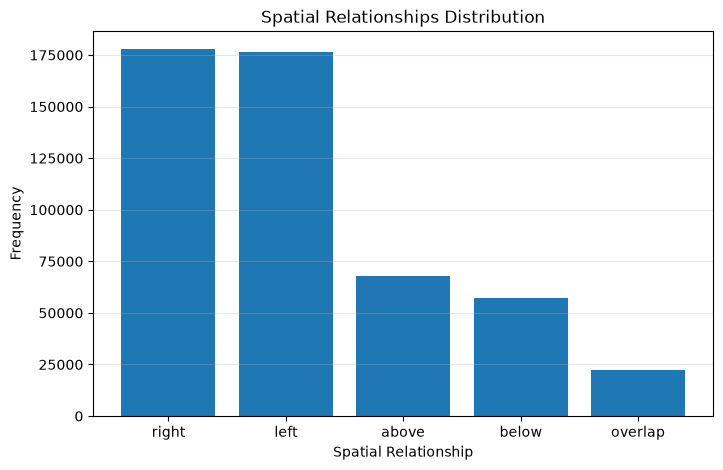

In [51]:
plt.figure(figsize=(8, 5))

plt.bar(
    relationship_counts["Relationship"],
    relationship_counts["Count"]
)

plt.title("Spatial Relationships Distribution")
plt.xlabel("Spatial Relationship")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "spatial_relationships_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 10.6. Most Frequent Object Pairs

This step identifies the object pairs that most frequently
appear together in the extracted spatial relationships.

The analysis groups object pairs by their categories
and their corresponding geometric relationship.

This helps identify common spatial arrangements
between objects in the dataset.

In [52]:
object_pair_counts = (
    relationships_df
    .groupby(["object_1", "relationship", "object_2"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(object_pair_counts.head(20))

,object_1,relationship,object_2,Count
6820,person,right,person,34486
6665,person,left,person,33056
6510,person,above,person,7243
6743,person,overlap,person,4608
2516,car,left,car,4276
2609,car,right,car,4206
6793,person,right,chair,4034
6638,person,left,chair,3874
3266,chair,left,chair,3499
2635,car,right,person,3471


### 10.7. Save Spatial Analysis Results

The extracted spatial relationships and their frequency
statistics are saved as CSV files.

These files preserve the results for documentation
and further analysis.

In [53]:
relationships_df.to_csv(
    DATA_DIR / "spatial_relationships.csv",
    index=False
)

relationship_counts.to_csv(
    DATA_DIR / "spatial_relationship_counts.csv",
    index=False
)

object_pair_counts.to_csv(
    DATA_DIR / "spatial_object_pairs.csv",
    index=False
)

print("Spatial analysis results saved successfully.")

Spatial analysis results saved successfully.


### 10.8. Results Interpretation

The spatial relationship analysis identified geometric
relationships between objects using their bounding box coordinates.

The results show that horizontal relationships are the most
frequent. The "right" relationship was detected 177,736 times,
while "left" was detected 176,493 times.

Vertical relationships were also identified, with 68,045
"above" relationships and 57,159 "below" relationships.

Overlapping bounding boxes accounted for 22,473 relationships.

The object pair analysis shows that person-person relationships
are among the most frequent combinations. Car-car and
person-chair relationships also appear frequently.

These results provide information about the geometric
arrangement of objects within the images.

It is important to note that the extracted relationships are
based on bounding box centers and overlap calculations.
They are geometric approximations and do not represent
verified semantic relationships.

Each object pair is processed once, and directional
relationships depend on the annotation order of the pair.

## Step 11: Object Co-occurrence Analysis

### Description
Object co-occurrence analysis identifies object categories
that frequently appear together in the same image.

Unlike spatial relationship analysis, this step does not
consider the positions of objects.

For example, an image containing a person and a bicycle
contributes to the co-occurrence count of these two categories.

### Objective
Identify frequent object category combinations and explore
the relationships between object categories across images.

### Method
The analysis uses COCO instance annotations.
For each image, unique object categories are extracted.
Pairs of categories appearing in the same image are then counted.

### 11.2. Prepare Object Categories per Image

In this step, object annotations are grouped by image ID.

For each image, we extract the unique object categories.
Repeated instances of the same category within an image
are counted only once for co-occurrence analysis.

This ensures that the analysis measures whether two categories
appear together in an image, rather than how many individual
objects of each category are present.

In [54]:
from itertools import combinations

# Group unique object categories by image
categories_per_image = (
    objects_df.groupby("image_id")["category_name"]
    .apply(lambda categories: sorted(set(categories)))
)

print("Total images with object annotations:", len(categories_per_image))

print("\nExample images and their object categories:")
display(categories_per_image.head(10))

Total images with object annotations: 10014

Example images and their object categories:


image_id
36                                    [person, umbrella]
73                                          [motorcycle]
89                        [book, knife, microwave, oven]
109                                 [bench, dog, person]
196    [bowl, broccoli, carrot, dining table, fork, s...
247                                      [airplane, car]
263                                           [elephant]
308                [clock, person, umbrella, wine glass]
312                                           [elephant]
315                   [chair, handbag, person, umbrella]
Name: category_name, dtype: object

### 11.3. Count Object Category Pairs

Each image is examined to identify pairs of distinct object
categories appearing together.

The combinations are generated without repetition.
For example, the pair (person, bicycle) is counted only once
per image, even if multiple persons or bicycles are present.

The frequency of each pair represents the number of images
in which both categories occur.

In [55]:
cooccurrence_counts = Counter()

for categories in categories_per_image:
    for pair in combinations(categories, 2):
        cooccurrence_counts[pair] += 1

cooccurrence_results = pd.DataFrame(
    [
        {
            "Object 1": pair[0],
            "Object 2": pair[1],
            "Image Count": count
        }
        for pair, count in cooccurrence_counts.items()
    ]
)

cooccurrence_results = cooccurrence_results.sort_values(
    "Image Count",
    ascending=False
).reset_index(drop=True)

print("Total unique object pairs:", len(cooccurrence_results))
display(cooccurrence_results.head(20))

Total unique object pairs: 1848


,Object 1,Object 2,Image Count
0,car,person,733
1,chair,person,707
2,handbag,person,538
3,dining table,person,461
4,backpack,person,450
5,chair,dining table,419
6,cup,person,384
7,cup,dining table,370
8,person,truck,368
9,bottle,person,367


### 11.4. Most Frequent Object Pairs Visualization

The 20 most frequent object category pairs are selected
and displayed using a horizontal bar chart.

This visualization highlights the combinations of objects
that most frequently appear together in the same images.

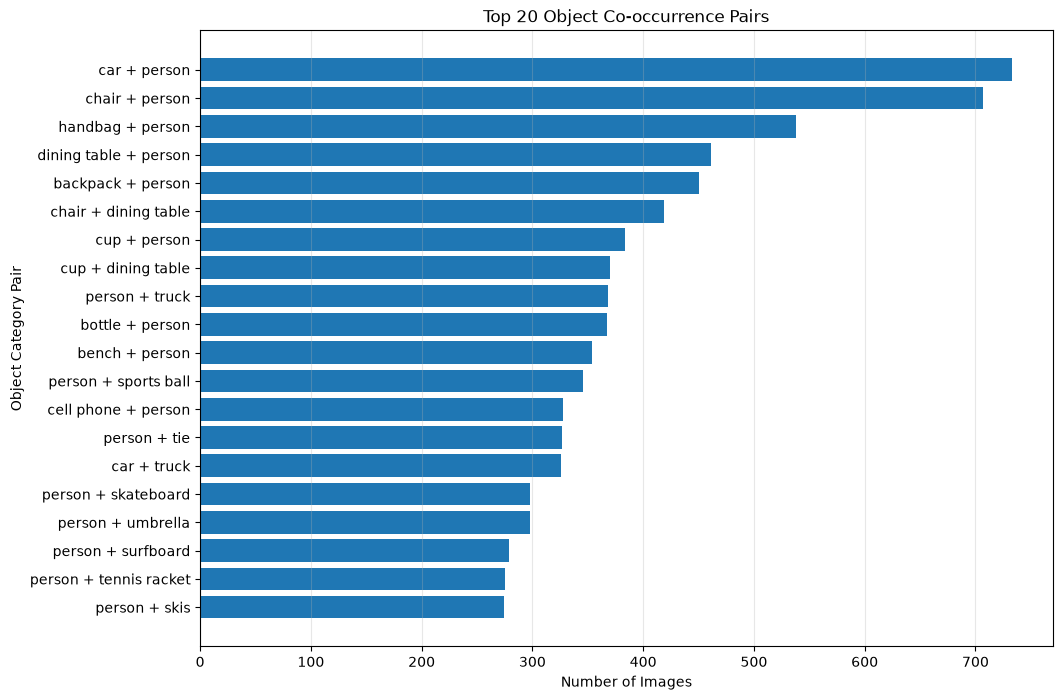

In [56]:
top_20_pairs = cooccurrence_results.head(20).copy()

top_20_pairs["Pair"] = (
    top_20_pairs["Object 1"] + " + " + top_20_pairs["Object 2"]
)

plt.figure(figsize=(11, 8))

plt.barh(
    top_20_pairs["Pair"][::-1],
    top_20_pairs["Image Count"][::-1]
)

plt.title("Top 20 Object Co-occurrence Pairs")
plt.xlabel("Number of Images")
plt.ylabel("Object Category Pair")
plt.grid(axis="x", alpha=0.3)

plt.savefig(
    VISUALIZATIONS_DIR / "top_20_object_cooccurrence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 11.5. Object Co-occurrence Matrix

A co-occurrence matrix is created to represent how frequently
object categories appear together across images.

To keep the visualization readable, the analysis focuses
on the 15 most frequent object categories.

Each matrix cell represents the number of images containing
both the row category and the column category.

The matrix is symmetric because the co-occurrence of category A
with category B is equal to the co-occurrence of category B
with category A.

The diagonal represents the number of images containing
each individual category.

In [57]:
# Select the 15 most frequent categories
top_15_categories = (
    objects_df["category_name"]
    .value_counts()
    .head(15)
    .index
    .tolist()
)

# Initialize the co-occurrence matrix
cooccurrence_matrix = pd.DataFrame(
    0,
    index=top_15_categories,
    columns=top_15_categories
)

# Count category occurrences per image
for categories in categories_per_image:
    selected_categories = [
        category
        for category in categories
        if category in top_15_categories
    ]

    # Fill diagonal and off-diagonal cells
    for category in selected_categories:
        cooccurrence_matrix.loc[category, category] += 1

    for category_1, category_2 in combinations(selected_categories, 2):
        cooccurrence_matrix.loc[category_1, category_2] += 1
        cooccurrence_matrix.loc[category_2, category_1] += 1

display(cooccurrence_matrix)

,person,car,chair,book,bottle,cup,dining table,bowl,traffic light,handbag,umbrella,truck,bird,boat,sheep
person,5489,733,707,189,367,384,461,241,225,538,298,368,62,173,37
car,733,1052,46,6,23,21,26,8,220,133,77,326,19,18,6
chair,707,46,1137,182,206,250,419,146,4,83,67,22,15,17,3
book,189,6,182,437,90,96,88,49,2,30,2,1,5,0,1
bottle,367,23,206,90,700,238,215,172,3,47,11,13,3,6,1
cup,384,21,250,96,238,772,370,225,3,48,11,6,4,1,1
dining table,461,26,419,88,215,370,959,255,1,44,24,6,2,7,0
bowl,241,8,146,49,172,225,255,586,2,25,4,8,5,2,0
traffic light,225,220,4,2,3,3,1,2,354,66,25,95,7,0,0
handbag,538,133,83,30,47,48,44,25,66,578,102,65,10,9,1


### 11.6. Co-occurrence Matrix Visualization

A heatmap is generated to visualize the co-occurrence matrix.

Each cell represents the number of images in which two
object categories appear together.

Darker and lighter regions help identify frequent and
less frequent object combinations.

The heatmap provides a visual overview of relationships
between the most frequent object categories.

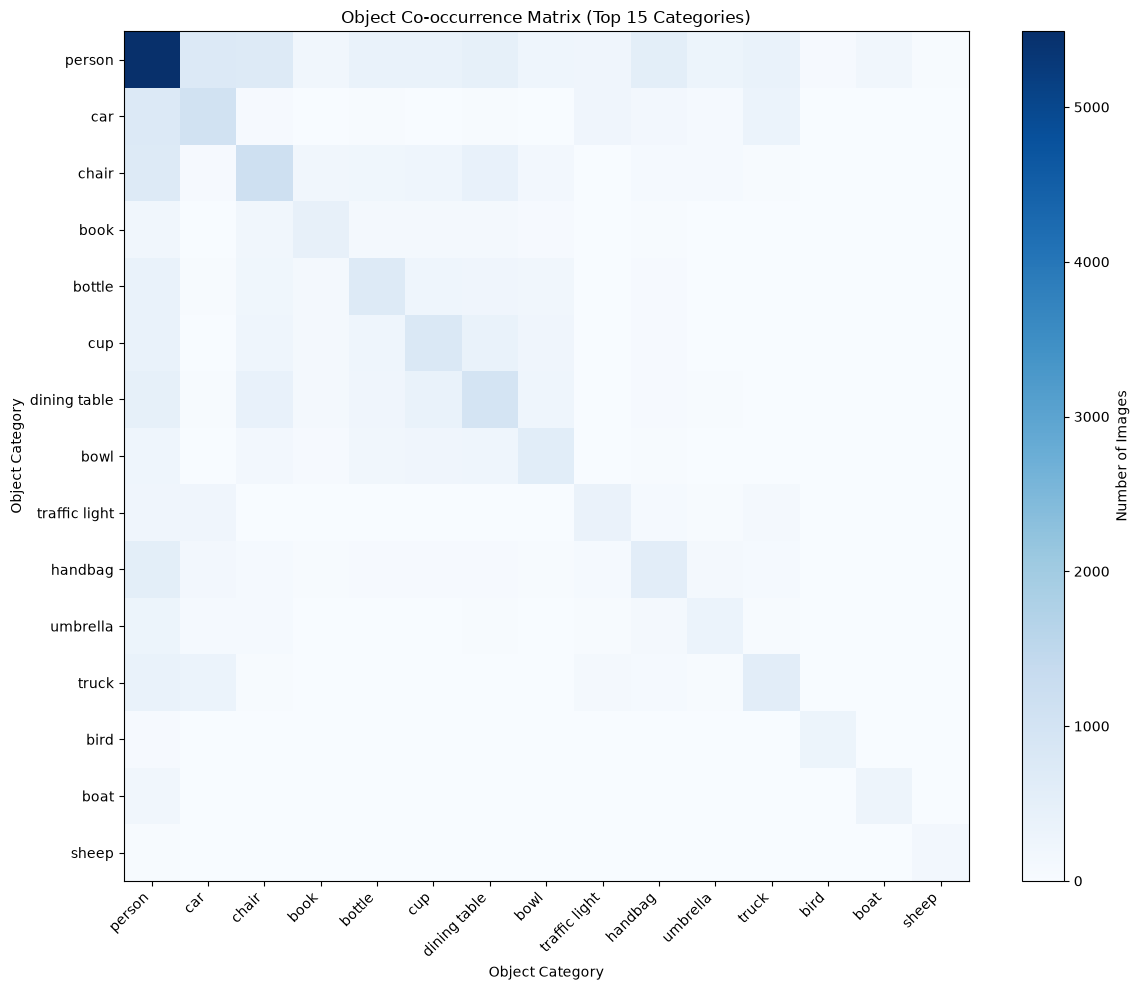

In [58]:
plt.figure(figsize=(12, 10))

plt.imshow(cooccurrence_matrix, cmap="Blues", aspect="auto")

plt.colorbar(label="Number of Images")

plt.xticks(
    range(len(top_15_categories)),
    top_15_categories,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(top_15_categories)),
    top_15_categories
)

plt.title("Object Co-occurrence Matrix (Top 15 Categories)")
plt.xlabel("Object Category")
plt.ylabel("Object Category")

plt.tight_layout()

plt.savefig(
    VISUALIZATIONS_DIR / "object_cooccurrence_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 11.7. Save Co-occurrence Results

The object co-occurrence results are saved as CSV files.

The following files are generated:
- cooccurrence_results.csv: all object category pairs and their counts.
- top_20_object_pairs.csv: the 20 most frequent object pairs.
- object_cooccurrence_matrix.csv: the co-occurrence matrix
  for the 15 most frequent categories.

These files preserve the statistical results for documentation
and further analysis.

In [59]:
cooccurrence_results.to_csv(
    DATA_DIR / "cooccurrence_results.csv",
    index=False
)

top_20_pairs.to_csv(
    DATA_DIR / "top_20_object_pairs.csv",
    index=False
)

cooccurrence_matrix.to_csv(
    DATA_DIR / "object_cooccurrence_matrix.csv"
)

print("Object co-occurrence results saved successfully.")

Object co-occurrence results saved successfully.


### 11.8 Results Interpretation

The object co-occurrence analysis identifies object categories that frequently appear together in the same images.

The most frequent combination is **car and person**, appearing together in 733 images. Other frequent combinations include **chair and person** (707 images), **handbag and person** (538 images), and **dining table and person** (461 images).

These results show that the person category frequently co-occurs with objects associated with everyday activities and environments. For example, chairs and dining tables are commonly found in indoor scenes, while cars, trucks, and traffic lights are associated with outdoor and transportation scenes.

The co-occurrence matrix provides a broader view of relationships between object categories. Its diagonal values represent the number of images containing each individual category, while off-diagonal values represent the number of images containing both categories.

This analysis can help describe scene composition and identify common object combinations in the dataset.

**Note:** Co-occurrence indicates that two categories appear in the same image. It does not necessarily mean that the objects interact or have a direct semantic relationship.

## Step 12: Final Statistical Summary

### Description
This step combines the main statistical results obtained during the dataset exploration and analysis.

### Objective
Provide a concise overview of the cleaned dataset, caption statistics, object annotations, scene complexity, and object co-occurrence.

### Method
A summary table is created using the results from the previous steps. The table is then exported as a CSV file for documentation.

## Step 12.1 Create the Summary Table

In [60]:
summary_data = [
    ["Training images", len(train_manifest)],
    ["Validation images", len(validation_manifest)],
    ["Total clean images", len(train_manifest) + len(validation_manifest)],
    ["Training captions", len(train_captions)],
    ["Validation captions", len(validation_captions)],
    ["Total captions", len(train_captions) + len(validation_captions)],
    ["Average captions per training image",
     round(len(train_captions) / len(train_manifest), 2)],
    ["Average caption length (words)", 10.44],
    ["Training vocabulary size", 9683],
    ["Local object annotations", len(local_annotations)],
    ["Object categories in original COCO dataset", len(categories)],
    ["Average objects per image", 7.23],
    ["Images without object annotations", 85],
    ["Unique object co-occurrence pairs", len(cooccurrence_results)]
]

summary_df = pd.DataFrame(
    summary_data,
    columns=["Metric", "Value"]
)

display(summary_df)

summary_df.to_csv(
    DATA_DIR / "final_statistical_summary.csv",
    index=False
)

print("Final statistical summary saved successfully.")

,Metric,Value
0,Training images,9999.00
1,Validation images,100.00
2,Total clean images,10099.00
3,Training captions,50018.00
4,Validation captions,503.00
5,Total captions,50521.00
6,Average captions per training image,5.00
7,Average caption length (words),10.44
8,Training vocabulary size,9683.00
9,Local object annotations,72998.00


Final statistical summary saved successfully.


### 12.2 Verify the Number of Object Categories

The original COCO instances annotation file contains 80 object categories.
The category count is verified directly from the original JSON file to avoid using an overwritten variable.

In [61]:
with open(INSTANCES_PATH, "r", encoding="utf-8") as file:
    instances_data = json.load(file)

correct_category_count = len(instances_data["categories"])

print("Verified COCO object categories:", correct_category_count)

summary_df.loc[
    summary_df["Metric"] == "Object categories in original COCO dataset",
    "Value"
] = correct_category_count

display(summary_df)

summary_df.to_csv(
    DATA_DIR / "final_statistical_summary.csv",
    index=False
)

print("Corrected statistical summary saved successfully.")

Verified COCO object categories: 80


,Metric,Value
0,Training images,9999.00
1,Validation images,100.00
2,Total clean images,10099.00
3,Training captions,50018.00
4,Validation captions,503.00
5,Total captions,50521.00
6,Average captions per training image,5.00
7,Average caption length (words),10.44
8,Training vocabulary size,9683.00
9,Local object annotations,72998.00


Corrected statistical summary saved successfully.


## Conclusion

This notebook presented a statistical analysis of the cleaned MS-COCO subset.

The analysis covered caption characteristics, object category frequencies, scene complexity, linguistic distribution, visual attributes, spatial relationships, and object co-occurrence.

The final cleaned dataset contains 9,999 training images and 100 validation images, with 50,521 associated captions.

The analysis results and visualizations were exported to the project directories for documentation and further preprocessing.

These results provide an initial understanding of the dataset and prepare it for the remaining Phase 1 tasks.